In [1]:
import matplotlib.pyplot as plt
import time
import tensorflow as tf
import numpy as np
import pandas as pd
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomZoom

In [2]:
train_path = (r"C:\Users\admin\Downloads\Dataset-20261112T113230Z-1-001\Dataset\Handwritten\mnist_train.csv")
test_path  = (r"C:\Users\admin\Downloads\Dataset-20261112T113230Z-1-001\Dataset\Handwritten\mnist_test.csv")

In [3]:
train_df = pd.read_csv(train_path)
test_df  = pd.read_csv(test_path)

In [5]:
x_train = train_df.drop('label', axis=1).values
y_train = train_df['label'].values

x_test = test_df.drop('label', axis=1).values
y_test = test_df['label'].values

In [6]:
x_train = x_train.reshape(-1, 28, 28, 1).astype("float32") / 255.0
x_test  = x_test.reshape(-1, 28, 28, 1).astype("float32") / 255.0

In [7]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(60000, 28, 28, 1)
(60000,)
(10000, 28, 28, 1)
(10000,)


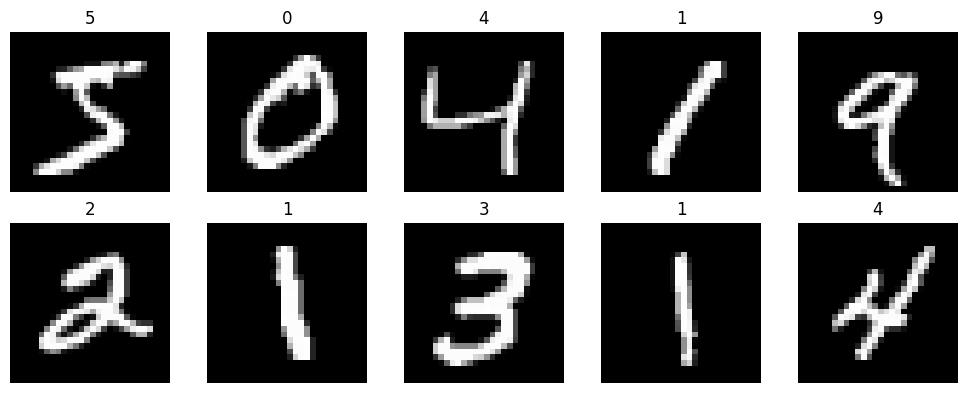

In [10]:
plt.figure(figsize=(10,4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='grey')
    plt.title(y_train[i])
    plt.axis("off")
        
plt.tight_layout()
plt.show()

In [11]:
mlp = Sequential([
    Flatten(input_shape=(28, 28, 1)),
    Dense(512, activation="relu"),
    Dropout(0.3),
    Dense(256, activation="relu"),
    Dropout(0.3),
    Dense(10, activation="softmax")
])
mlp.summary()

C:\Users\admin\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │         401,920 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 535,818 (2.04 MB)

 Trainable params: 535,818 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
mlp.compile(
    optimizer = "Adam",
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [13]:
start = time.time()

history_mlp = mlp.fit(x_train, y_train,
                      epochs=10,
                      batch_size=32,
                      validation_split=0.1)

mlp_time = time.time() - start

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9211 - loss: 0.2611 - val_accuracy: 0.9708 - val_loss: 0.1017
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9622 - loss: 0.1267 - val_accuracy: 0.9762 - val_loss: 0.0818
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9706 - loss: 0.0988 - val_accuracy: 0.9785 - val_loss: 0.0722
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9746 - loss: 0.0831 - val_accuracy: 0.9778 - val_loss: 0.0731
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9769 - loss: 0.0737 - val_accuracy: 0.9825 - val_loss: 0.0667
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9797 - loss: 0.0669 - val_accuracy: 0.9790 - val_loss: 0.0753
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9802 - loss: 0.0611 - val_accuracy: 0.9803 - val_loss: 0.0767
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9826 - loss: 0.0541 - 

In [14]:
cnn = Sequential([
    Input(shape=(28, 28, 1)),
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1),

    Conv2D(32, (3, 3), activation = "relu", padding = "same"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation = "relu", padding = "same"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation = "relu"),
    Dropout(0.4),
    Dense(10, activation = "softmax")
])
cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)             │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_rotation (RandomRotation)     │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_zoom (RandomZoom)             │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 14, 14, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 3136)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │         401,536 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
cnn.compile(
    optimizer = "Adam",
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [16]:
start = time.time()
history_cnn = cnn.fit(
    x_train, y_train,
    epochs = 10,
    batch_size = 32,
    validation_split = 0.1
)
cnn_time = time.time() - start

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.8276 - loss: 0.5369 - val_accuracy: 0.9633 - val_loss: 0.1241
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9191 - loss: 0.2599 - val_accuracy: 0.9753 - val_loss: 0.0844
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - accuracy: 0.9360 - loss: 0.2067 - val_accuracy: 0.9790 - val_loss: 0.0713
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.9464 - loss: 0.1748 - val_accuracy: 0.9768 - val_loss: 0.0785
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.9517 - loss: 0.1575 - val_accuracy: 0.9827 - val_loss: 0.0655
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.9554 - loss: 0.1469 - val_accuracy: 0.9830 - val_loss: 0.0673
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9593 - loss: 0.1322 - val_accuracy: 0.9825 - val_loss: 0.0646
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - accuracy: 0.9612 - loss: 0

In [17]:
mlp_loss, mlp_acc = mlp.evaluate(x_test, y_test)
cnn_loss, cnn_acc = cnn.evaluate(x_test, y_test)

print("Training loss for mlp:", round(mlp_loss * 100, 2), "%")
print("Training loss for cnn:", round(cnn_loss * 100, 2), "%")
print("Training accuracy for mlp:", round(mlp_acc * 100, 2), "%")
print("Training accuracy for cnn:", round(mlp_acc * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9799 - loss: 0.0765
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9828 - loss: 0.0538
Training loss for mlp: 7.65 %
Training loss for cnn: 5.38 %
Training accuracy for mlp: 97.99 %
Training accuracy for cnn: 97.99 %


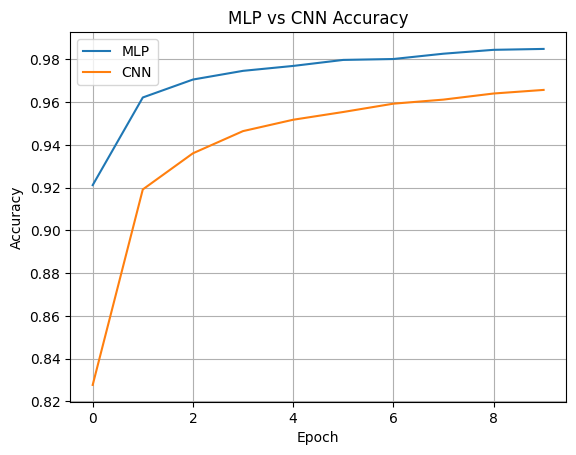

In [18]:
plt.plot(history_mlp.history["accuracy"], label = "MLP")
plt.plot(history_cnn.history["accuracy"], label = "CNN")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MLP vs CNN Accuracy")
plt.legend()
plt.grid(True)
plt.show()

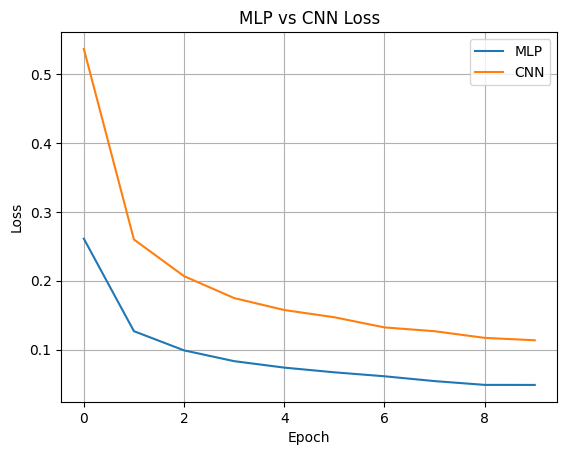

In [19]:
plt.plot(history_mlp.history["loss"], label = "MLP")
plt.plot(history_cnn.history["loss"], label = "CNN")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP vs CNN Loss")
plt.legend()
plt.grid(True)
plt.show()

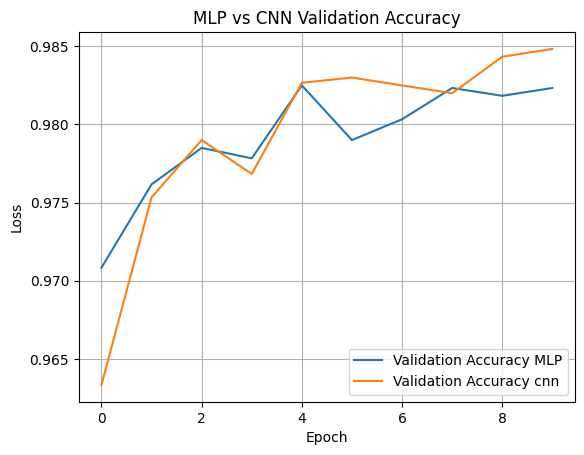

In [20]:
plt.plot(history_mlp.history["val_accuracy"], label = "Validation Accuracy MLP")
plt.plot(history_cnn.history["val_accuracy"], label = "Validation Accuracy cnn")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP vs CNN Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

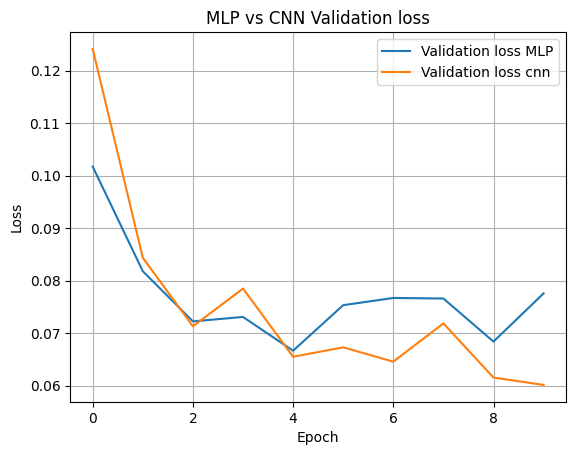

In [21]:
plt.plot(history_mlp.history["val_loss"], label = "Validation loss MLP")
plt.plot(history_cnn.history["val_loss"], label = "Validation loss cnn")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP vs CNN Validation loss")
plt.legend()
plt.grid(True)
plt.show()